<a href="https://colab.research.google.com/github/Oli-via123/AI-ML-Practice-and-Projects/blob/main/AI%20and%20ML%20Practice/Classification%20_Model/Classification_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Libraries

In [ ]:
# Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split       # This is the library needed for splitting your data into train and test set
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

### Load and Inspect the Dataset

* To read in the csv file, you right click on your data and the copy path. Paste the path you copied as an argument in the in the `pd.read_csv()` built-in function.

* Note: It's advisable you have your notebook and dataset in the same folder.

In [ ]:
# Let's read in the data
iris = pd.read_csv(r"Iris_dataset.csv")

# View the first 5
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Let's check the shape of the dataset
iris.shape  # The shape shows the (row and column) of the dataframe

(150, 6)

In [ ]:
# Let's get basic information about the dataset
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
# Check for missing values
iris.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [ ]:
# Let's do a statistical summary
iris.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [ ]:
# Check for the distribution of the target variable (Species)
iris["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

We can see from the data inspection that:  
* The dataset consists of 150 rows and 6 columns
* There are no missing values
* The dataset has 3 target variable that are evenly distributed into 50 each

### Exploratory Data Analysis

In [ ]:
# Let's check all column names
print(iris.columns.tolist())

['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


* Pairplot  

    A pairplot is a grid of plots that helps you quickly visualize the relationships between all pairs of numeric variables in a dataset. Interpreting it involves examining the diagonal plots for individual variable distributions and the off-diagonal scatter plots for pairwise relationships.

    The diagonal shows the distribution shape of each variable

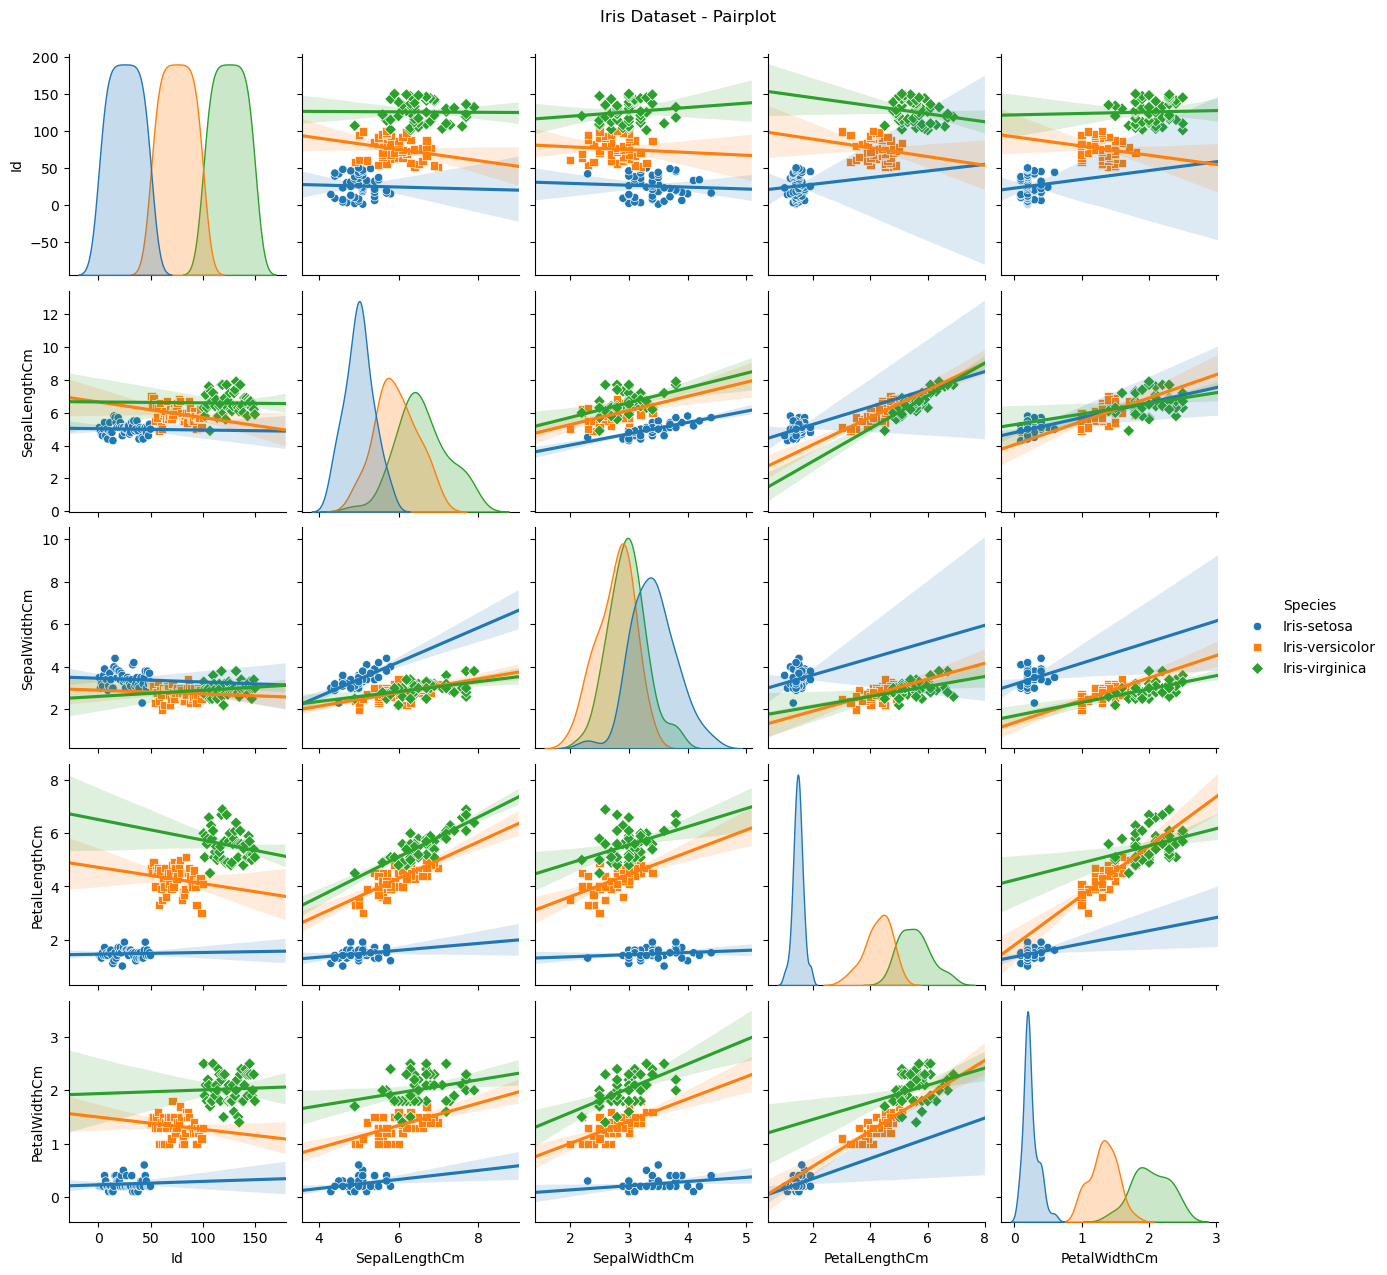

In [ ]:
# Let's do a pairplot to see relationships between features
sns.pairplot(iris, hue="Species", markers=["o", "s", "D"]).map_offdiag(sns.regplot, scatter=False, truncate=False)
plt.suptitle("Iris Dataset - Pairplot", y=1.02)
plt.show()

* Correlation Heatmap  

    A correlation heatmap is a data visualization method that displays the correlation matrix between multiple variables using colors, indicating the strength and direction of relationships.  

    Correlation checks include:  
    Correlation Coefficient (r): A numerical value ranging from -1.0 to +1.0, representing the strength and direction of the linear relationship.  
    Direction: A positive sign (+) means variables move in the same direction, while a negative sign (-) means they move in opposite directions.  
    Strength: Values closer to +1 or -1 indicate a stronger positive or negative relationship, while values closer to 0 indicate a weaker linear relationship.

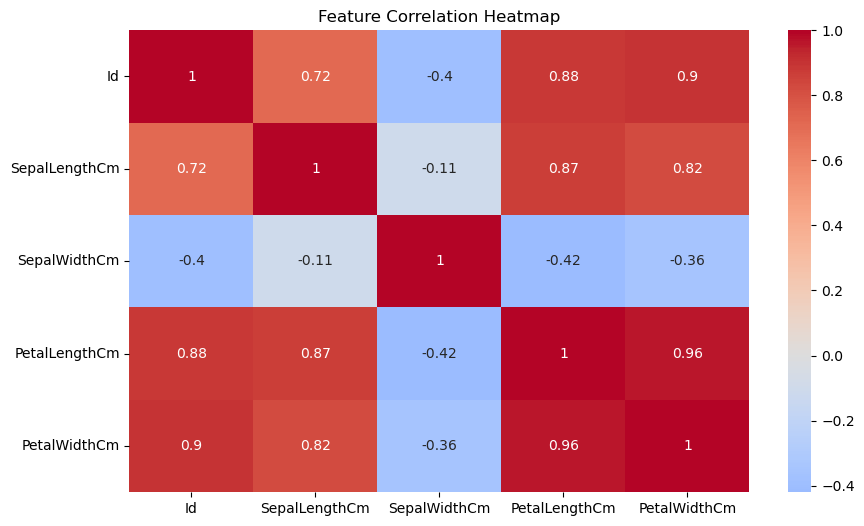

In [ ]:
# Let's see the correlation heatmap (excluding non-numeric columns)
plt.figure(figsize=(10, 6))

# Select only numeric columns for correlation
numeric_cols = iris.select_dtypes(include=[np.number]).columns
sns.heatmap(iris[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

* Box Plot

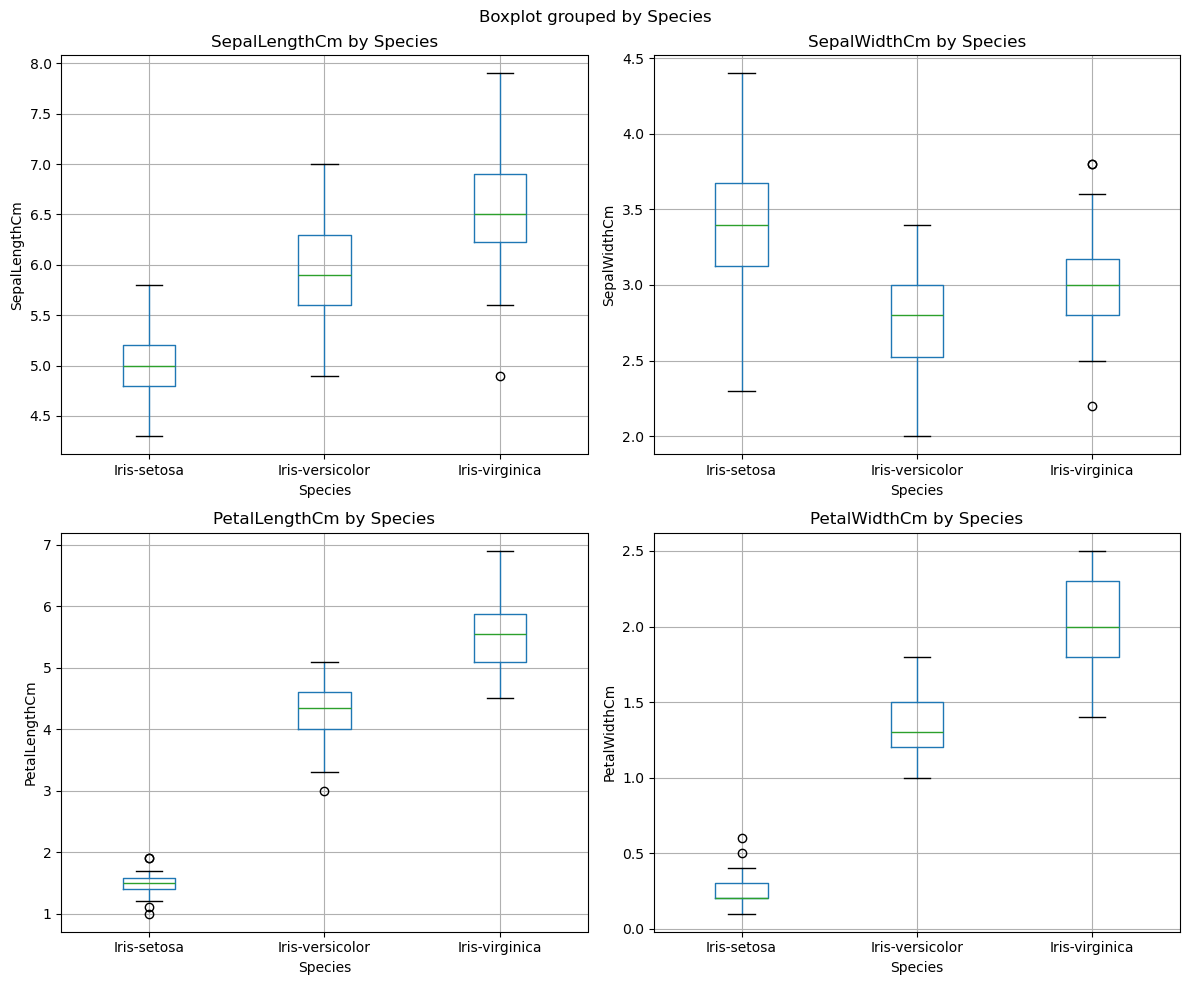

In [ ]:
# Box plots to see feature distributions by species
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = [col for col in iris.columns if col not in ['Id', 'Species']]

for idx, feature in enumerate(features):
    ax = axes[idx // 2, idx % 2]
    iris.boxplot(column=feature, by='Species', ax=ax)
    ax.set_title(f'{feature} by Species')
    ax.set_xlabel('Species')
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

### Feature Selection

In [ ]:
# First, let's drop the Id column since it's not a real feature
if 'Id' in iris.columns:
    iris = iris.drop('Id', axis=1)

# Separate features (X) and target (y)
X = iris.drop('Species', axis=1)
y = iris['Species']

# Let's see the features
print("~" * 20)
print(" Features (X):")
print("~" * 20)
print(X.head())

# Shape of featrues
print("\nShape of X:", X.shape)
print()

# Let's see the target/label
print("~" * 20)
print("Target (y):")
print("~" * 20)
print(y.head())

# shape of target
print("\nShape of y:", y.shape)

# See unique values
print("\nUnique species:", y.unique())

~~~~~~~~~~~~~~~~~~~~
 Features (X):
~~~~~~~~~~~~~~~~~~~~
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

Shape of X: (150, 4)

~~~~~~~~~~~~~~~~~~~~
Target (y):
~~~~~~~~~~~~~~~~~~~~
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

Shape of y: (150,)

Unique species: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


### Split Dataset

In [ ]:
# Split the data: 80% training, 20% testing
# stratify=y ensures each split has the same proportion of each species
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=234, stratify=y
)

# Check the splits
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print()

print("~" * 38)
print(" Training set species distribution:")
print("~" * 38)
print(y_train.value_counts())
print()

print("~" * 38)
print(" Testing set species distribution:")
print("~" * 38)
print(y_test.value_counts())

Training set size: (120, 4)
Testing set size: (30, 4)

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Training set species distribution:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Species
Iris-virginica     40
Iris-setosa        40
Iris-versicolor    40
Name: count, dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Testing set species distribution:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Species
Iris-virginica     10
Iris-versicolor    10
Iris-setosa        10
Name: count, dtype: int64


### Feature Scaling

In [ ]:
# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform both training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Check the scaling
print("~" * 40)
print("Original training data (first 5 rows):")
print("~" * 40)
print(X_train.head())
print()

print("~" * 40)
print("Scaled training data (first 5 rows):")
print("~" * 40)
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).head())
print()

print("~" * 45)
print("Mean of scaled features (should be close to 0):")
print("~" * 45)
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).mean())
print()

print("~" * 45)
print("Std of scaled features (should be close to 1):")
print("~" * 45)
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).std())

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Original training data (first 5 rows):
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
136            6.3           3.4            5.6           2.4
138            6.0           3.0            4.8           1.8
32             5.2           4.1            1.5           0.1
135            7.7           3.0            6.1           2.3
148            6.2           3.4            5.4           2.3

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Scaled training data (first 5 rows):
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0       0.595871      0.786810       1.050914      1.547506
1       0.222804     -0.116704       0.596874      0.770516
2      -0.772041      2.367960      -1.276042     -1.430958
3       2.336850     -0.116704       1.334689      1.418008
4       0.471515      0.786810       0.937404      1.418008

~~~~~~~~~~~~~~~~~~~~~~~~~~

### Model Training

In [ ]:
# Initialize models
model = LogisticRegression(random_state=234, max_iter=200)

# Train model
print("Model training in action\n")
model.fit(X_train_scaled, y_train)

Model training in action



,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,234
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


### Make Prediction

In [ ]:
prediction = model.predict(X_test_scaled)

# Let's peek at the predictions
print("\nLogistic Regression predictions (first 10):")
print(prediction[:10])

print("\nActual values (first 10):")
print(y_test.values[:10])


Logistic Regression predictions (first 10):
['Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-setosa']

Actual values (first 10):
['Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-setosa']


### Evaluate Model

In [ ]:
# Calculate accuracy the model
print("=" * 23)
print(" MODEL ACCURACY SCORES")
print("=" * 23)
accuracy = accuracy_score(y_test, prediction)
print(f"{accuracy:.4f} ({accuracy*100:.2f}%)")
print("\n" + "="*60)


# Detailed classification report for the best model
print(f"       DETAILED CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, prediction))

# See confusion Matrix for the model
print("\n" + "=" * 18)
print(f" CONFUSION MATRIX")
print("=" * 18)
cm = confusion_matrix(y_test, prediction)
print(cm)

 MODEL ACCURACY SCORES
0.9333 (93.33%)

       DETAILED CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30


 CONFUSION MATRIX
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


### Visualize Confusion Matrix

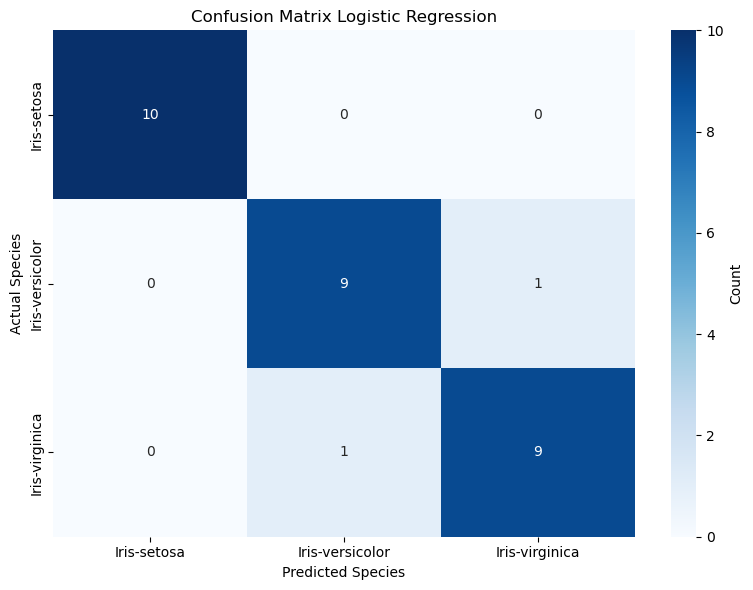

In [ ]:
# Visualize confusion matrix for the model
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, prediction)

# Get unique species names in the correct order
species_names = sorted(y_test.unique())

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=species_names,
            yticklabels=species_names,
            cbar_kws={'label': 'Count'})
plt.ylabel('Actual Species')
plt.xlabel('Predicted Species')
plt.title(f'Confusion Matrix Logistic Regression')
plt.tight_layout()
plt.show()

### Save Model

In [ ]:
import joblib

# Save the model
model_filename = 'best_iris_model.pkl'
joblib.dump(model, model_filename)
print(f"Model saved as '{model_filename}'")

# Also save the scaler (important for making predictions later)
scaler_filename = 'iris_scaler.pkl'
joblib.dump(scaler, scaler_filename)
print(f"Scaler saved as '{scaler_filename}'")

Model saved as 'best_iris_model.pkl'
Scaler saved as 'iris_scaler.pkl'


In [ ]:
# Test loading the model back
loaded_model = joblib.load(model_filename)
loaded_scaler = joblib.load(scaler_filename)
print("\nModel and scaler loaded successfully!")

# Verify it works by making a test prediction
test_prediction = loaded_model.predict(loaded_scaler.transform(X_test[:5]))
print("\nTest predictions with loaded model:")
print(test_prediction)
print("\nActual values:")
print(y_test[:5].values)


Model and scaler loaded successfully!

Test predictions with loaded model:
['Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica']

Actual values:
['Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica']
